[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch04_Lab02_2026_MNIST_10Digit_Interactive.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 4: Stacking Neurons: Dense Layers and the MLP** (Part I: The Learning Machine). Also used in Chapter 12.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=4](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=4)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 🔢 MNIST Digit Recognition (0-9) - Interactive Edition
## Train a Neural Network & Test with YOUR Handwritten Digits!

**What you'll do:**
1. Train a neural network to recognize digits 0-9
2. Upload YOUR OWN handwritten digits
3. Watch the AI automatically detect, crop, and classify them!

---

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * The data overview figure drew the ten sample digits on top of the bar chart; they now sit in their own grid beside it.
> * **Runs outside Colab too.** `from google.colab import files` stopped the notebook on its first code cell anywhere else. Uploads now go through `get_images()`: the upload button in Colab, a `MY_IMAGES` list in Jupyter, or demo "photos" drawn by the notebook, so every cell runs.
> * **Better photo preprocessing.** The old function used an adaptive threshold with an 11-pixel window, which on a phone photo keeps only the *outline* of each stroke (hollow digits), and it kept only the largest blob. The new one uses Otsu's threshold, keeps every stroke, thickens thin lines and follows MNIST's own recipe (20×20 box, centred by centre of mass). Tested on ten demo digits with a quickly trained copy of this network: 5/10 right before, 9/10 after.
> * `keras.Input(shape=(784,))` replaces the deprecated `input_shape=`; training prints one line per epoch (`verbose=2`).
> * "Trained on 60,000 images" corrected to 54,000: `validation_split=0.1` holds 6,000 back for validation.

In [1]:
# Install TensorFlow and OpenCV (if needed)
!pip install -q tensorflow opencv-python

## 📦 Cell 1: Import Libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import io

# Set random seed
np.random.seed(42)
tf.random.set_seed(42)

print("✅ All libraries loaded!")
print(f"TensorFlow: {tf.__version__}, OpenCV: {cv2.__version__}")

✅ All libraries loaded!
TensorFlow: 2.21.0, OpenCV: 4.13.0


---
## 📊 Cell 2: Load and Visualize MNIST Data

📥 Loading MNIST dataset...



Training set: 60,000 images
Test set: 10,000 images
Image size: 28×28


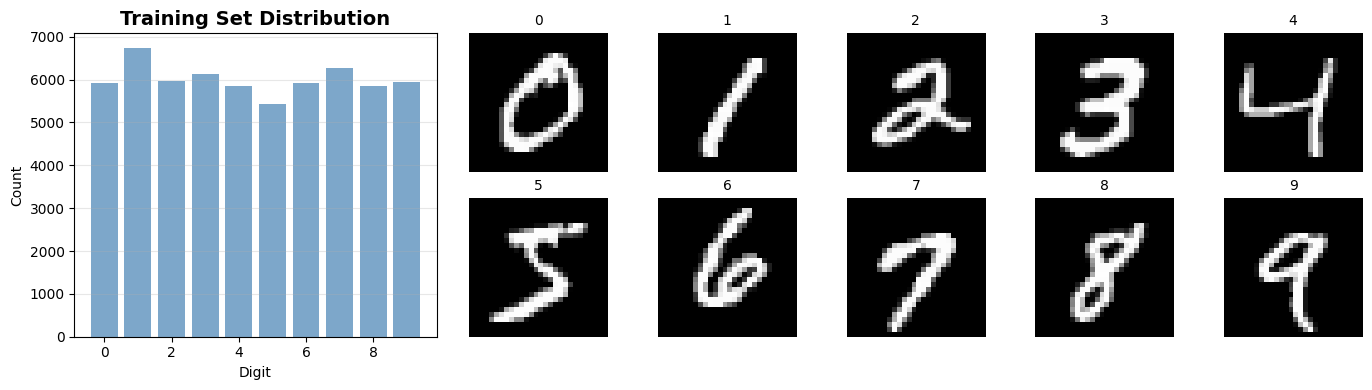

In [3]:
print("📥 Loading MNIST dataset...\n")

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print(f"Training set: {X_train.shape[0]:,} images")
print(f"Test set: {X_test.shape[0]:,} images")
print(f"Image size: {X_train.shape[1]}×{X_train.shape[2]}")

# Show digit distribution
fig = plt.figure(figsize=(14, 4))
grid = fig.add_gridspec(2, 7)
axes = [fig.add_subplot(grid[:, :2])]

# Count per digit
unique, counts = np.unique(y_train, return_counts=True)
axes[0].bar(unique, counts, color='steelblue', alpha=0.7)
axes[0].set_title('Training Set Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Digit')
axes[0].set_ylabel('Count')
axes[0].grid(True, alpha=0.3, axis='y')

# Sample images: one of each digit, in a 2 x 5 grid to the right of the chart
for digit in range(10):
    idx = np.where(y_train == digit)[0][0]
    ax_sub = fig.add_subplot(grid[digit // 5, 2 + digit % 5])
    ax_sub.imshow(X_train[idx], cmap='gray')
    ax_sub.set_title(str(digit), fontsize=10)
    ax_sub.axis('off')

plt.tight_layout()
plt.show()

---
## 🔧 Cell 3: Prepare Data

In [4]:
print("🔧 Preparing data...\n")

# Normalize
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

# Flatten
X_train_flat = X_train_norm.reshape(X_train_norm.shape[0], -1)
X_test_flat = X_test_norm.reshape(X_test_norm.shape[0], -1)

print(f"✅ Data prepared!")
print(f"Shape: {X_train_flat.shape} (60,000 images × 784 pixels)")
print(f"Labels: {np.unique(y_train)} (digits 0-9)")

🔧 Preparing data...

✅ Data prepared!
Shape: (60000, 784) (60,000 images × 784 pixels)
Labels: [0 1 2 3 4 5 6 7 8 9] (digits 0-9)


---
## 🏗️ Cell 4: Build Neural Network

In [5]:
print("🏗️ Building neural network...\n")

model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')  # 10 digits!
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

print("\n✅ Model ready to train!")

🏗️ Building neural network...



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)


✅ Model ready to train!


---
## 🎓 Cell 5: Train the Model

In [6]:
print("🎓 Training...\n")

history = model.fit(
    X_train_flat, y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.1,
    verbose=2   # one line per epoch
)

print(f"\n✅ Training complete!")
print(f"Final accuracy: {history.history['accuracy'][-1]:.4f}")

🎓 Training...

Epoch 1/30


422/422 - 4s - 9ms/step - accuracy: 0.8519 - loss: 0.4917 - val_accuracy: 0.9583 - val_loss: 0.1479


Epoch 2/30


422/422 - 2s - 5ms/step - accuracy: 0.9358 - loss: 0.2176 - val_accuracy: 0.9682 - val_loss: 0.1075


Epoch 3/30


422/422 - 3s - 7ms/step - accuracy: 0.9516 - loss: 0.1643 - val_accuracy: 0.9718 - val_loss: 0.0925


... (51 outputs left out)

422/422 - 3s - 6ms/step - accuracy: 0.9903 - loss: 0.0294 - val_accuracy: 0.9833 - val_loss: 0.0736


Epoch 30/30


422/422 - 3s - 7ms/step - accuracy: 0.9894 - loss: 0.0314 - val_accuracy: 0.9835 - val_loss: 0.0725



✅ Training complete!
Final accuracy: 0.9894


---
## 📈 Cell 6: Training Visualizations

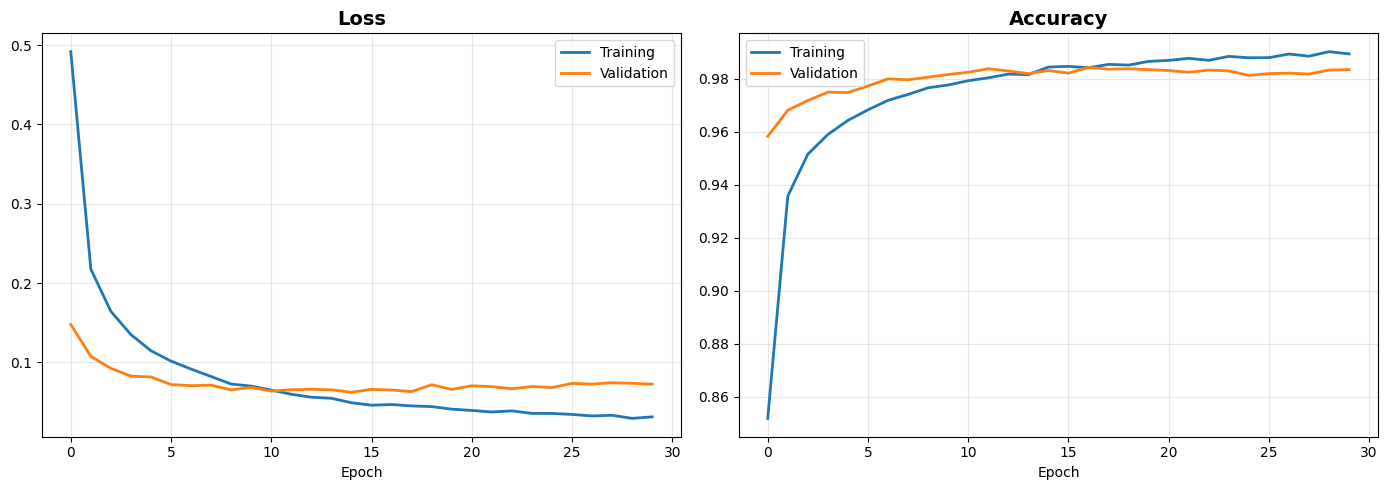

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Training', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation', linewidth=2)
axes[0].set_title('Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Training', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
axes[1].set_title('Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 🎯 Cell 7: Evaluate on Test Set

In [8]:
print("🎯 Evaluating on test set...\n")

test_loss, test_accuracy = model.evaluate(X_test_flat, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

# Get predictions
y_pred = np.argmax(model.predict(X_test_flat, verbose=0), axis=1)

print(f"\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3))

🎯 Evaluating on test set...



Test Loss: 0.0784
Test Accuracy: 0.9798 (97.98%)



Classification Report:
              precision    recall  f1-score   support

           0      0.984     0.993     0.988       980
           1      0.988     0.992     0.990      1135
           2      0.977     0.981     0.979      1032
           3      0.977     0.979     0.978      1010
           4      0.980     0.980     0.980       982
           5      0.986     0.973     0.980       892
           6      0.979     0.983     0.981       958
           7      0.983     0.969     0.976      1028
           8      0.966     0.976     0.971       974
           9      0.977     0.970     0.974      1009

    accuracy                          0.980     10000
   macro avg      0.980     0.980     0.980     10000
weighted avg      0.980     0.980     0.980     10000



---
## 🎨 Cell 8: Confusion Matrix

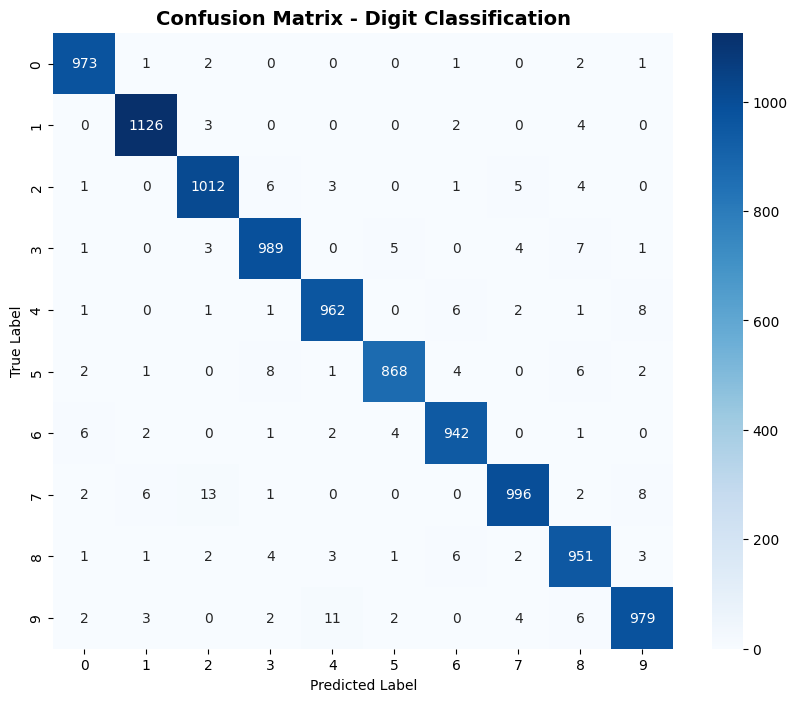

Diagonal = Correct predictions
Off-diagonal = Mistakes


In [9]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix - Digit Classification', fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print("Diagonal = Correct predictions")
print("Off-diagonal = Mistakes")

---
## 🔍 Cell 9: Sample Predictions

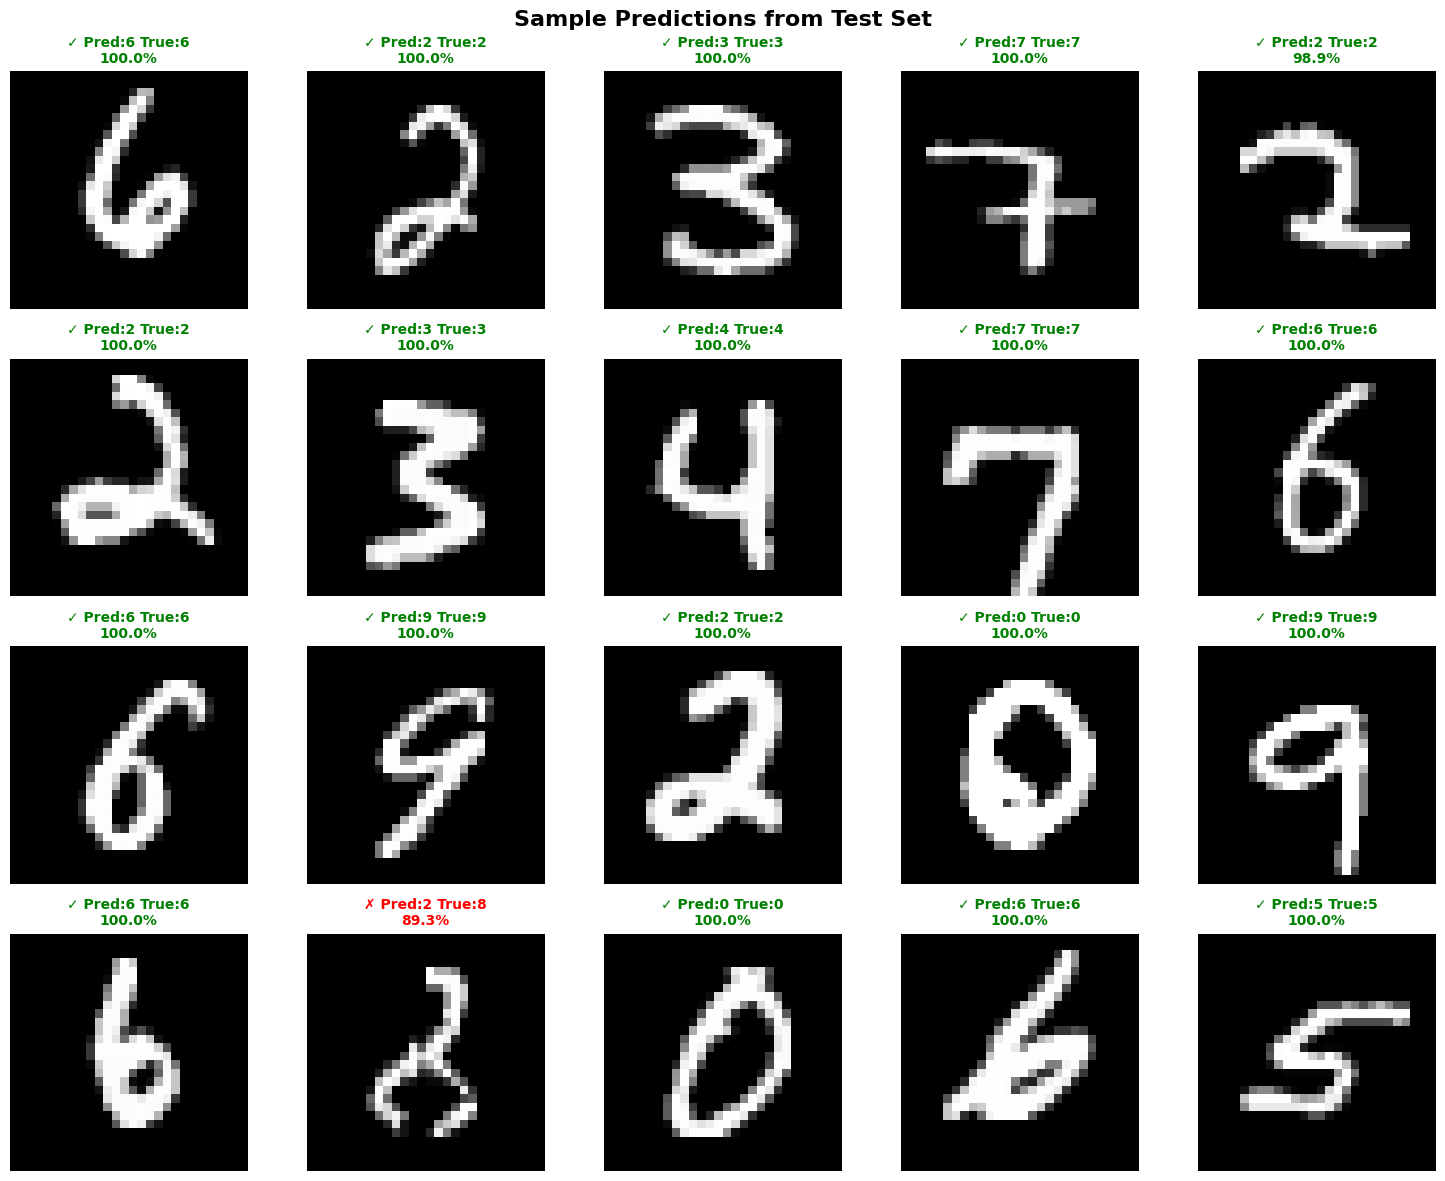

In [10]:
# Get predictions with probabilities
predictions_proba = model.predict(X_test_flat, verbose=0)

# Show 20 random examples
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.flatten()

indices = np.random.choice(len(X_test), 20, replace=False)

for i, idx in enumerate(indices):
    pred = np.argmax(predictions_proba[idx])
    true = y_test[idx]
    conf = predictions_proba[idx][pred] * 100

    axes[i].imshow(X_test[idx], cmap='gray')

    color = 'green' if pred == true else 'red'
    status = '✓' if pred == true else '✗'

    axes[i].set_title(f'{status} Pred:{pred} True:{true}\n{conf:.1f}%',
                     color=color, fontweight='bold', fontsize=10)
    axes[i].axis('off')

plt.suptitle('Sample Predictions from Test Set', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

---
---
# 🎨 INTERACTIVE SECTION - Upload YOUR Digits!
---
---

## 🖼️ Cell 10: AUTO-CROP PREPROCESSING FUNCTION

This function turns a photo of your digit into the kind of picture the network was trained on:
1. Separates the ink from the paper (Otsu's threshold)
2. Finds the digit (all its strokes) and crops it
3. Thickens thin pen strokes to MNIST's stroke width
4. Scales the digit into a 20×20 box and centres it in 28×28 by its centre of mass (exactly how MNIST was made)
5. Prepares it for the network

**No manual cropping needed!**

> **Why so much care?** The network only knows what MNIST digits look like. A photo that is processed differently
> (thin strokes, off-centre, hollow outlines) is a *different kind of input*, and accuracy drops sharply. We tested
> both versions on ten clear demo digits with a quickly trained copy of this network: the first version got only 5
> right, this one got 9.

In [11]:
def auto_crop_and_preprocess(image_path, verbose=True):
    """
    Turn a photo of ONE handwritten digit (dark pen on light paper) into an MNIST-style input.
    Returns: original image, processed 28x28 image (0-1), network-ready input of shape (1, 784)

    It copies the recipe MNIST itself used: white digit on black, digit scaled to fit a 20x20 box
    (keeping its shape), then placed in a 28x28 frame so that its centre of mass sits in the middle.
    """
    say = print if verbose else (lambda *a, **k: None)
    img = cv2.imread(image_path)
    if img is None:
        say("❌ Could not read image!")
        return None, None, None
    original = img.copy()
    say(f"✓ Image loaded: {img.shape[1]}×{img.shape[0]} pixels")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Otsu's method picks ONE threshold between paper and ink for the whole photo.
    # (A small adaptive-threshold window keeps only the EDGES of a thick marker stroke: hollow digits.)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    say("✓ Separated ink from paper (Otsu threshold)")

    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        say("⚠️ No digit detected! Try a clearer image.")
        return None, None, None
    # Keep every blob at least 5% the size of the biggest: a 5, or a 7 with a bar, is often two strokes.
    areas = [cv2.contourArea(c) for c in contours]
    keep = [c for c, a in zip(contours, areas) if a >= 0.05 * max(areas)]
    x, y, w, h = cv2.boundingRect(np.vstack(keep))
    digit = thresh[y:y+h, x:x+w]
    say(f"✓ Digit found at x={x}, y={y}, size {w}×{h}")

    # MNIST strokes are about 1/8 of the digit's height; thicken thin pen lines to match.
    stroke = 2 * cv2.distanceTransform(digit, cv2.DIST_L2, 3).max()
    target = max(w, h) / 8
    if stroke < target:
        k = int(target - stroke) | 1
        digit = cv2.dilate(digit, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
        say(f"✓ Thickened thin strokes ({stroke:.0f} → about {target:.0f} pixels)")

    # Fit into a 20x20 box, keeping the aspect ratio
    scale = 20.0 / max(w, h)
    small = cv2.resize(digit, (max(1, round(w * scale)), max(1, round(h * scale))), interpolation=cv2.INTER_AREA)
    frame = np.zeros((28, 28), dtype=np.float32)
    top, left = (28 - small.shape[0]) // 2, (28 - small.shape[1]) // 2
    frame[top:top+small.shape[0], left:left+small.shape[1]] = small

    # Shift so the centre of mass is in the middle, as in MNIST
    total = frame.sum()
    if total > 0:
        rows, cols = np.indices(frame.shape)
        dy = int(round(13.5 - (rows * frame).sum() / total))
        dx = int(round(13.5 - (cols * frame).sum() / total))
        frame = cv2.warpAffine(frame, np.float32([[1, 0, dx], [0, 1, dy]]), (28, 28))
    say("✓ Scaled to 20×20 and centred in 28×28 (the MNIST recipe)")

    normalized = np.clip(frame / 255.0, 0, 1).astype('float32')
    network_input = normalized.reshape(1, -1)
    say("✓ Ready for classification!\n")
    return original, normalized, network_input

# Where do the images come from?
#  • In Google Colab: an upload button appears (cancel it to use the demo images instead).
#  • In Jupyter / VS Code: put your own file names in MY_IMAGES below.
#  • With neither, the notebook draws demo "photos" so every cell still runs and shows the whole pipeline.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

MY_IMAGES = []      # e.g. ["my_seven.jpg", "my_three.png"]  (used when not in Colab)


def make_demo_photo(digit, path=None, seed=0):
    """Draw a digit with a pen-like script font on slightly uneven paper, the way a phone photo looks."""
    rng = np.random.default_rng(seed + digit)
    H, W = 480, 400
    paper = np.linspace(225, 245, W)[None, :] * np.ones((H, 1))          # uneven lighting
    paper = paper + rng.normal(0, 4, (H, W))                             # sensor noise
    ink = np.zeros((H, W), np.uint8)
    cv2.putText(ink, str(digit), (95, 390), cv2.FONT_HERSHEY_SCRIPT_SIMPLEX, 11, 255, 26, cv2.LINE_AA)
    M = cv2.getRotationMatrix2D((W / 2, H / 2), rng.uniform(-8, 8), 1.0)  # a slightly tilted hand
    ink = cv2.warpAffine(ink, M, (W, H)).astype(float) / 255
    photo = paper * (1 - ink) + 35 * ink                                 # dark ink on light paper
    photo = np.clip(photo, 0, 255).astype(np.uint8)
    path = path or f"demo_digit_{digit}.png"
    cv2.imwrite(path, cv2.cvtColor(photo, cv2.COLOR_GRAY2BGR))
    return path


def get_images(demo_digits=(3,)):
    """Return a list of image file names to classify."""
    if IN_COLAB:
        uploaded = files.upload()
        if uploaded:
            return list(uploaded.keys())
    if MY_IMAGES:
        return list(MY_IMAGES)
    print(f"(No upload, so using demo photo(s) of {', '.join(map(str, demo_digits))}. "
          "Add your own file names to MY_IMAGES, or run this in Colab to upload.)\n")
    return [make_demo_photo(d) for d in demo_digits]

print("✅ Auto-crop preprocessing function ready!")
print("Running in Colab:", IN_COLAB)

✅ Auto-crop preprocessing function ready!
Running in Colab: False


---
## 🎯 Cell 11: UPLOAD & CLASSIFY YOUR DIGIT!

**Instructions:**
1. Write a digit (0-9) on white paper with a dark pen
2. Take a photo (JPG/PNG)
3. Upload below
4. Watch the AI auto-detect, crop, and classify!

**The AI will automatically:**
- Find your digit in the image
- Crop it perfectly
- Resize to 28×28
- Tell you which digit (0-9) it is!

📤 UPLOAD YOUR HANDWRITTEN DIGIT
✏️  Write any digit (0-9) on WHITE paper with DARK pen
📸 Take a photo (can include background - AI will auto-crop!)
⬆️  Click 'Choose Files' below (in Colab), or list your files in MY_IMAGES

(No upload, so using demo photo(s) of 7. Add your own file names to MY_IMAGES, or run this in Colab to upload.)


Processing: demo_digit_7.png

✓ Image loaded: 400×480 pixels
✓ Separated ink from paper (Otsu threshold)
✓ Digit found at x=119, y=142, size 181×260
✓ Scaled to 20×20 and centred in 28×28 (the MNIST recipe)
✓ Ready for classification!



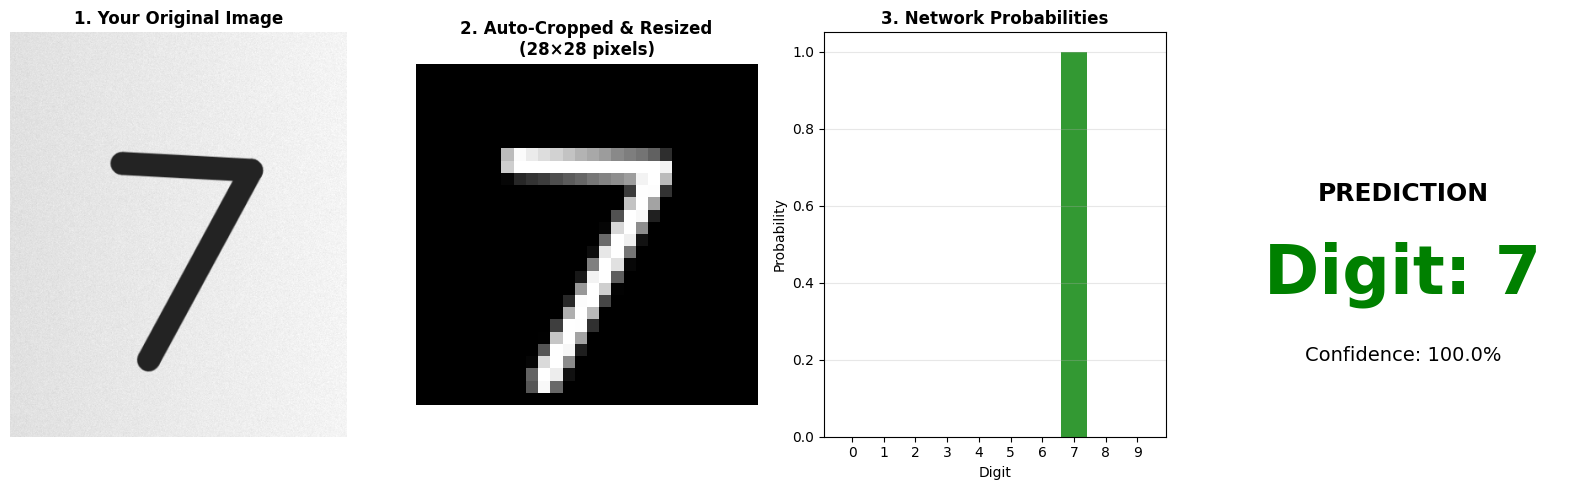


🎯 CLASSIFICATION RESULTS
Predicted Digit: 7
Confidence: 100.00%

All probabilities:
  Digit 0:  0.00% 
  Digit 1:  0.00% 
  Digit 2:  0.00% 
  Digit 3:  0.00% 
  Digit 4:  0.00% 
  Digit 5:  0.00% 
  Digit 6:  0.00% 
  Digit 7: 100.00% █████████████████████████████
  Digit 8:  0.00% 
  Digit 9:  0.00% 


In [12]:
def classify_uploaded_digit(image_path):
    """Complete pipeline: auto-crop and classify"""

    original, processed, network_input = auto_crop_and_preprocess(image_path)

    if processed is None:
        return

    # Get prediction
    prediction_proba = model.predict(network_input, verbose=0)[0]
    predicted_digit = np.argmax(prediction_proba)
    confidence = prediction_proba[predicted_digit]

    # Visualize
    fig = plt.figure(figsize=(16, 5))

    # Original image
    ax1 = plt.subplot(1, 4, 1)
    ax1.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    ax1.set_title('1. Your Original Image', fontsize=12, fontweight='bold')
    ax1.axis('off')

    # Processed 28×28
    ax2 = plt.subplot(1, 4, 2)
    ax2.imshow(processed, cmap='gray')
    ax2.set_title('2. Auto-Cropped & Resized\n(28×28 pixels)', fontsize=12, fontweight='bold')
    ax2.axis('off')

    # Prediction probabilities
    ax3 = plt.subplot(1, 4, 3)
    colors = ['green' if i == predicted_digit else 'lightgray' for i in range(10)]
    ax3.bar(range(10), prediction_proba, color=colors, alpha=0.8)
    ax3.set_title('3. Network Probabilities', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Digit')
    ax3.set_ylabel('Probability')
    ax3.set_xticks(range(10))
    ax3.grid(True, alpha=0.3, axis='y')

    # Final prediction
    ax4 = plt.subplot(1, 4, 4)
    ax4.text(0.5, 0.6, 'PREDICTION', ha='center', va='center',
            fontsize=18, fontweight='bold')
    ax4.text(0.5, 0.4, f'Digit: {predicted_digit}', ha='center', va='center',
            fontsize=48, fontweight='bold', color='green')
    ax4.text(0.5, 0.2, f'Confidence: {confidence*100:.1f}%', ha='center', va='center',
            fontsize=14)
    ax4.set_xlim(0, 1)
    ax4.set_ylim(0, 1)
    ax4.axis('off')

    plt.tight_layout()
    plt.show()

    # Print detailed results
    print(f"\n{'='*60}")
    print(f"🎯 CLASSIFICATION RESULTS")
    print(f"{'='*60}")
    print(f"Predicted Digit: {predicted_digit}")
    print(f"Confidence: {confidence*100:.2f}%")
    print(f"\nAll probabilities:")
    for i, prob in enumerate(prediction_proba):
        bar = '█' * int(prob * 30)
        print(f"  Digit {i}: {prob*100:5.2f}% {bar}")
    print(f"{'='*60}")

# Upload interface
print("📤 UPLOAD YOUR HANDWRITTEN DIGIT")
print("="*60)
print("✏️  Write any digit (0-9) on WHITE paper with DARK pen")
print("📸 Take a photo (can include background - AI will auto-crop!)")
print("⬆️  Click 'Choose Files' below (in Colab), or list your files in MY_IMAGES")
print("="*60)
print()

for filename in get_images(demo_digits=(7,)):
    print(f"\n{'='*60}")
    print(f"Processing: {filename}")
    print(f"{'='*60}\n")
    classify_uploaded_digit(filename)

---
## 📦 Cell 12: BATCH UPLOAD - Test Multiple Digits!

Upload multiple digit images at once!

📦 BATCH UPLOAD - Multiple Digits
Upload multiple images and see all results!

(No upload, so using demo photo(s) of 0, 1, 2, 3, 4, 5, 6, 7, 8, 9. Add your own file names to MY_IMAGES, or run this in Colab to upload.)




Processing: demo_digit_0.png...

Processing: demo_digit_1.png...



Processing: demo_digit_2.png...

Processing: demo_digit_3.png...



Processing: demo_digit_4.png...

Processing: demo_digit_5.png...



Processing: demo_digit_6.png...



Processing: demo_digit_7.png...



Processing: demo_digit_8.png...



Processing: demo_digit_9.png...


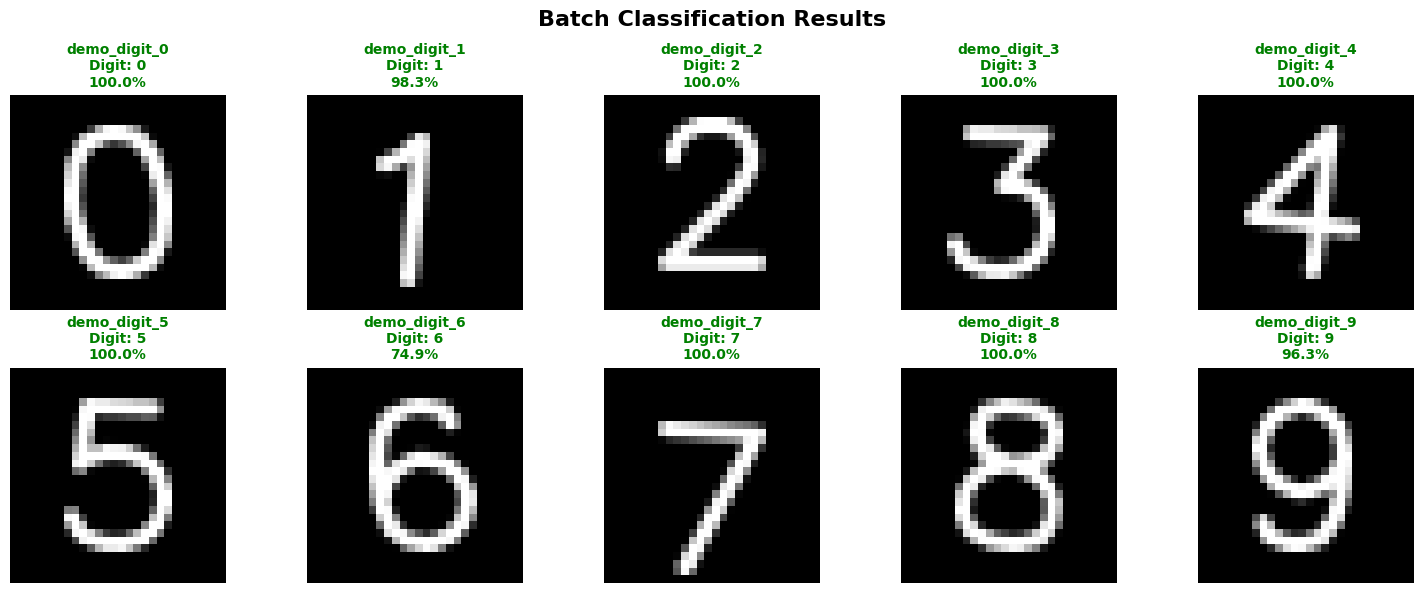


BATCH RESULTS
File                      Predicted    Confidence  
----------------------------------------------------------------------
demo_digit_0.png          0            100.00%
demo_digit_1.png          1             98.25%
demo_digit_2.png          2            100.00%
demo_digit_3.png          3            100.00%
demo_digit_4.png          4            100.00%
demo_digit_5.png          5             99.99%
demo_digit_6.png          6             74.89%
demo_digit_7.png          7            100.00%
demo_digit_8.png          8             99.99%
demo_digit_9.png          9             96.30%
Total processed: 10


In [13]:
print("📦 BATCH UPLOAD - Multiple Digits")
print("="*60)
print("Upload multiple images and see all results!")
print("="*60)
print()

uploaded_batch = get_images(demo_digits=range(10))

results = []

for filename in uploaded_batch:
    print(f"\nProcessing: {filename}...")

    original, processed, network_input = auto_crop_and_preprocess(filename, verbose=False)

    if processed is not None:
        prediction_proba = model.predict(network_input, verbose=0)[0]
        predicted_digit = np.argmax(prediction_proba)
        confidence = prediction_proba[predicted_digit]

        results.append({
            'filename': filename,
            'processed': processed,
            'prediction': predicted_digit,
            'confidence': confidence,
            'probabilities': prediction_proba
        })

# Visualize all results
if len(results) > 0:
    n = len(results)
    cols = min(5, n)
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
    if n == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for i, result in enumerate(results):
        axes[i].imshow(result['processed'], cmap='gray')
        axes[i].set_title(
            f"{result['filename'][:12]}\nDigit: {result['prediction']}\n{result['confidence']*100:.1f}%",
            fontsize=10, fontweight='bold', color='green'
        )
        axes[i].axis('off')

    for i in range(len(results), len(axes)):
        axes[i].axis('off')

    plt.suptitle('Batch Classification Results', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Summary table
    print(f"\n{'='*70}")
    print(f"BATCH RESULTS")
    print(f"{'='*70}")
    print(f"{'File':<25} {'Predicted':<12} {'Confidence':<12}")
    print(f"{'-'*70}")
    for r in results:
        print(f"{r['filename']:<25} {r['prediction']:<12} {r['confidence']*100:>6.2f}%")
    print(f"{'='*70}")
    print(f"Total processed: {len(results)}")
else:
    print("No valid images processed.")

---
## 💡 Cell 13: Tips for Best Results

In [14]:
print("💡 TIPS FOR BEST DIGIT RECOGNITION")
print("="*70)

print("\n✅ RECOMMENDED:")
print("  • Use DARK pen/marker on WHITE paper")
print("  • Write digits LARGE and BOLD")
print("  • Write similar to how the MNIST examples look")
print("  • Good lighting (natural light is best)")
print("  • Take photo straight-on, not at an angle")
print("  • One digit per image works best")

print("\n❌ AVOID:")
print("  • Light pencils or faint writing")
print("  • Tiny digits (write bigger!)")
print("  • Fancy or decorative fonts")
print("  • Blurry or low-quality photos")
print("  • Colored/patterned backgrounds")
print("  • Multiple digits in one image")

print("\n🎯 HOW IT WORKS:")
print("  1. Converts your image to grayscale")
print("  2. Separates ink from paper with one global (Otsu) threshold")
print("  3. Finds all the digit's strokes and crops around them")
print("  4. Thickens thin pen strokes to MNIST's stroke width")
print("  5. Scales the digit into a 20×20 box (keeping its shape)")
print("  6. Centres it in 28×28 by its centre of mass (the MNIST recipe)")
print("  7. Feeds it to the neural network")
print("  8. Returns digit (0-9) with confidence!")

print("\n📊 MODEL ACCURACY:")
print(f"  Test set accuracy: {test_accuracy*100:.2f}%")
print(f"  This model was trained on 54,000 handwritten digits (6,000 more were held out for validation)!")
print(f"  It recognizes which digit (0-9), not just if it's a digit.")

print("="*70)

💡 TIPS FOR BEST DIGIT RECOGNITION

✅ RECOMMENDED:
  • Use DARK pen/marker on WHITE paper
  • Write digits LARGE and BOLD
  • Write similar to how the MNIST examples look
  • Good lighting (natural light is best)
  • Take photo straight-on, not at an angle
  • One digit per image works best

❌ AVOID:
  • Light pencils or faint writing
  • Tiny digits (write bigger!)
  • Fancy or decorative fonts
  • Blurry or low-quality photos
  • Colored/patterned backgrounds
  • Multiple digits in one image

🎯 HOW IT WORKS:
  1. Converts your image to grayscale
  2. Separates ink from paper with one global (Otsu) threshold
  3. Finds all the digit's strokes and crops around them
  4. Thickens thin pen strokes to MNIST's stroke width
  5. Scales the digit into a 20×20 box (keeping its shape)
  6. Centres it in 28×28 by its centre of mass (the MNIST recipe)
  7. Feeds it to the neural network
  8. Returns digit (0-9) with confidence!

📊 MODEL ACCURACY:
  Test set accuracy: 97.98%
  This model was train

---
## 🎓 Cell 14: Summary

In [15]:
print(f"\n{'='*70}")
print("🎓 PROJECT COMPLETE - DIGIT RECOGNITION (0-9)")
print(f"{'='*70}")

print("\n🧠 WHAT WE BUILT:")
print("  • Neural network with 128→64→10 architecture")
print("  • Multi-class classification (10 digits: 0-9)")
print("  • Softmax output layer for probabilities")
print("  • Auto-crop preprocessing pipeline")

print("\n📊 MODEL PERFORMANCE:")
print(f"  • Training accuracy: {history.history['accuracy'][-1]*100:.2f}%")
print(f"  • Test accuracy: {test_accuracy*100:.2f}%")
print(f"  • Trained on: 54,000 images (+6,000 for validation)")
print(f"  • Tested on: 10,000 images")

print("\n🎯 KEY FEATURES:")
print("  • Automatic digit detection (no manual cropping!)")
print("  • Handles various image sizes and lighting")
print("  • Real-time classification with confidence scores")
print("  • Batch processing for multiple images")

print("\n🚀 NEXT STEPS:")
print("  • Try Convolutional Neural Networks (CNNs)")
print("  • Add data augmentation for better accuracy")
print("  • Deploy as a web app (Streamlit/Gradio)")
print("  • Extend to recognize letters (A-Z)")
print("  • Try other datasets (Fashion-MNIST, CIFAR-10)")

print(f"\n{'='*70}")
print("✨ Congratulations! You built a working digit recognizer! ✨")
print(f"{'='*70}")


🎓 PROJECT COMPLETE - DIGIT RECOGNITION (0-9)

🧠 WHAT WE BUILT:
  • Neural network with 128→64→10 architecture
  • Multi-class classification (10 digits: 0-9)
  • Softmax output layer for probabilities
  • Auto-crop preprocessing pipeline

📊 MODEL PERFORMANCE:
  • Training accuracy: 98.94%
  • Test accuracy: 97.98%
  • Trained on: 54,000 images (+6,000 for validation)
  • Tested on: 10,000 images

🎯 KEY FEATURES:
  • Automatic digit detection (no manual cropping!)
  • Handles various image sizes and lighting
  • Real-time classification with confidence scores
  • Batch processing for multiple images

🚀 NEXT STEPS:
  • Try Convolutional Neural Networks (CNNs)
  • Add data augmentation for better accuracy
  • Deploy as a web app (Streamlit/Gradio)
  • Extend to recognize letters (A-Z)
  • Try other datasets (Fashion-MNIST, CIFAR-10)

✨ Congratulations! You built a working digit recognizer! ✨
